# 01. MuJoCo 기초 및 물리 시뮬레이션 입문 (MuJoCo Basics)

이 노트북은 Google DeepMind의 [공식 MuJoCo Python 튜토리얼](https://github.com/google-deepmind/mujoco)을 기반으로, **Windows 환경**에서 로보틱스 시뮬레이션을 처음 배우는 분들을 위해 한국어 설명과 함께 재구성한 튜토리얼입니다.

### 학습 목표
1. **MJCF(XML) 모델링 기초**: `<mujoco>`, `<worldbody>`, `<geom>`, `<body/>`, `<joint/>` 등 로봇 및 물리 환경 정의 방법 익히기
2. **핵심 데이터 구조**: 정적 모델 정보를 담는 `mjModel`과 동적 시뮬레이션 상태를 담는 `mjData` 이해하기
3. **자유도(DoF)와 일반화 좌표계**: 로봇 공학의 핵심인 일반화 위치(`qpos`)와 일반화 속도(`qvel`), 쿼터니언(Quaternion) 표현 이해하기
4. **시뮬레이션 및 수치 적분**: 타임스텝(`timestep`), 적분기(`Euler`, `RK4`), 에너지 보존 및 수치 발산(Divergence) 분석하기
5. **접촉(Contact)·마찰(Friction)·액추에이터·센서**: 물리적 상호작용과 로봇 센서/구동기 시뮬레이션 다루기
6. **고급 렌더링 및 시각화**: 깊이(Depth)/세그멘테이션(Segmentation) 카메라, 카메라 투영 행렬, 3D 궤적 그리기 및 동적 카메라 제어

In [1]:
import mujoco
import mediapy as media
import matplotlib.pyplot as plt
import numpy as np

import time
import itertools

# Windows 환경 초기화 (내장 FFmpeg 자동 연결 및 한글 폰트 설정)
from utils.notebook_setup import init_notebook
init_notebook()

In [2]:
xml = """
<mujoco>
  <worldbody>
    <geom name="red_box" type="box" size=".2 .2 .2" rgba="1 0 0 1"/>
    <geom name="green_sphere" pos=".2 .2 .2" size=".1" rgba="0 1 0 1"/>
  </worldbody>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(xml)

위 `xml` 문자열은 MuJoCo의 모델링 언어인 **[MJCF](https://mujoco.readthedocs.io/en/latest/modeling.html)**(XML 기반)로 작성되었습니다.
- 유일한 필수 태그는 `<mujoco>`입니다. 가장 작은 유효한 MJCF 모델은 완전히 비어 있는 `<mujoco/>`입니다.
- 모든 물리적 요소는 최상위 바디(top-level body)이자 직교 좌표계(Cartesian coordinates)의 전역 원점(Global Origin)을 의미하는 `<worldbody>` 내부에 배치됩니다.
- 여기서는 월드 내부에 `red_box`와 `green_sphere`라는 두 개의 기하 물체(`geom`)를 정의했습니다.
- **질문:** `red_box`에는 위치(`pos`)가 없고, `green_sphere`에는 형태(`type`)가 지정되어 있지 않습니다. 왜 그럴까요?
  - **답변:** MJCF 속성들은 **기본값(default values)**을 가지고 있기 때문입니다. 위치(`pos`)의 기본값은 `0 0 0`(원점)이며, 기하 형태(`type`)의 기본값은 `sphere`(구)입니다. 자세한 MJCF 문법은 [XML Reference 문서](https://mujoco.readthedocs.io/en/latest/XMLreference.html)에서 확인할 수 있습니다.

`from_xml_string()` 메서드는 모델 컴파일러를 호출하여 이진(binary) 형태의 `mjModel` 인스턴스를 생성합니다.

## 1. `mjModel`: 정적 모델 정보

MuJoCo의 `mjModel`은 **모델 명세(model description)**, 즉 **시간이 지나도 변하지 않는 정적인 물리량과 구조 정보**를 담고 있습니다. `mjModel`의 전체 필드 설명은 C 헤더 파일인 [`mjmodel.h`](https://github.com/google-deepmind/mujoco/blob/main/include/mujoco/mjmodel.h) 하단에서 확인할 수 있습니다.

예를 들어 씬(scene)에 존재하는 기하 물체(`geom`)의 개수인 `ngeom`과 각 물체의 색상 및 투명도(`rgba`) 배열인 `geom_rgba`를 확인해 보겠습니다:

In [3]:
model.ngeom

2

In [4]:
model.geom_rgba

array([[1., 0., 0., 1.],
       [0., 1., 0., 1.]], dtype=float32)

## 2. 이름 기반 접근 (Named Access)

MuJoCo Python 바인딩은 객체의 이름을 이용해 직관적으로 데이터에 접근할 수 있는 [Named Accessor](https://mujoco.readthedocs.io/en/latest/python.html#named-access) 기능을 제공합니다. `model.geom()`에 이름 문자열을 넣지 않고 호출하면, 현재 모델에서 사용할 수 있는 유효한 이름 목록을 친절하게 에러 메시지로 알려줍니다.

In [5]:
try:
  model.geom()
except KeyError as e:
  print(e)

"Invalid name ''. Valid names: ['green_sphere', 'red_box']"


이름을 지정하여 호출하면 해당 객체가 가진 모든 속성(property)들을 한눈에 볼 수 있습니다:

In [6]:
model.geom('green_sphere')

<_MjModelGeomViews
  bodyid: array([0], dtype=int32)
  conaffinity: array([1], dtype=int32)
  condim: array([3], dtype=int32)
  contype: array([1], dtype=int32)
  dataid: array([-1], dtype=int32)
  friction: array([1.e+00, 5.e-03, 1.e-04])
  gap: array([0.])
  group: array([0], dtype=int32)
  id: 1
  margin: array([0.])
  matid: array([-1], dtype=int32)
  name: 'green_sphere'
  pos: array([0.2, 0.2, 0.2])
  priority: array([0], dtype=int32)
  quat: array([1., 0., 0., 0.])
  rbound: array([0.1])
  rgba: array([0., 1., 0., 1.], dtype=float32)
  sameframe: array([0], dtype=uint8)
  size: array([0.1, 0. , 0. ])
  solimp: array([9.0e-01, 9.5e-01, 1.0e-03, 5.0e-01, 2.0e+00])
  solmix: array([1.])
  solref: array([0.02, 1.  ])
  type: array([2], dtype=int32)
  user: array([], dtype=float64)
>

이제 `green_sphere`의 `rgba` 색상 값을 읽어 보겠습니다:

In [7]:
model.geom('green_sphere').rgba

array([0., 1., 0., 1.], dtype=float32)

이 기능은 내부적으로 MuJoCo C API의 [`mj_name2id`](https://mujoco.readthedocs.io/en/latest/APIreference/APIfunctions.html#mj-name2id) 함수를 호출하여 인덱스(ID)를 찾는 과정을 편리하게 단축해 준 것입니다:

In [8]:
id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_GEOM, 'green_sphere')
model.geom_rgba[id, :]

array([0., 1., 0., 1.], dtype=float32)

마찬가지로 읽기 전용 속성인 `id`와 `name`을 사용하면 객체 이름에서 숫자 ID로, 또는 숫자 ID에서 이름으로 쉽게 변환할 수 있습니다:

In [9]:
print('id of "red_box":      ', model.geom('red_box').id)
print('id of "green_sphere": ', model.geom('green_sphere').id)
print('name of geom 0:       ', model.geom(0).name)
print('name of body 0:       ', model.body(0).name)

id of "green_sphere":  0
name of geom 0:  red_box
name of body 0:  world


참고로 0번 바디(`body 0`)는 항상 전역 배경인 `world`이며 이름을 변경할 수 없습니다.

`id`와 `name` 속성은 파이썬 리스트 컴프리헨션(list comprehension)으로 모델 구조를 탐색할 때 매우 유용합니다:

In [10]:
[model.geom(i).name for i in range(model.ngeom)]

['red_box', 'green_sphere']

## 3. `mjData`: 동적 시뮬레이션 상태

`mjData`는 시뮬레이션의 **현재 상태(state)**와 그 상태로부터 파생되는 모든 동적 물리량을 담고 있습니다.
시뮬레이션의 기본 상태는 **시간(`data.time`)**, **일반화 위치(`data.qpos`, Generalized positions)**, 그리고 **일반화 속도(`data.qvel`, Generalized velocities)**로 구성됩니다.
새로운 `mjData` 인스턴스를 생성하려면 앞서 만든 `mjModel`만 전달하면 됩니다:

In [11]:
data = mujoco.MjData(model)

`mjData`에는 상태로부터 계산되는 **파생 물리량(functions of the state)**도 저장됩니다. 예를 들어 월드 좌표계(world frame) 기준 각 기하 물체의 3차원 직교 좌표 `(x, y, z)`는 `data.geom_xpos`에 저장됩니다:

In [12]:
print(data.geom_xpos)

[[0. 0. 0.]
 [0. 0. 0.]]


잠깐, 왜 두 물체 모두 위치가 원점 `(0, 0, 0)`으로 나올까요? 분명 `green_sphere`는 `(0.2, 0.2, 0.2)`만큼 떨어진 곳에 배치했는데요!

그 이유는 MuJoCo에서 **`mjData`의 파생 물리량들은 명시적으로 순방향 계산(propagation) 함수를 호출해야 업데이트되기 때문**입니다.
물체들의 전역 직교 좌표(Cartesian pose)를 계산하기 위해 필요한 최소한의 함수는 정기구학(Forward Kinematics)을 수행하는 [`mj_kinematics`](https://mujoco.readthedocs.io/en/latest/APIreference/APIfunctions.html#mj-kinematics)입니다(카메라와 조명 제외).

In [13]:
mujoco.mj_kinematics(model, data)
print('배열 직접 접근 (raw access):\n', data.geom_xpos)

# MjData 역시 이름 기반 접근(named access)을 지원합니다:
print('\n이름 기반 접근 (named access):\n', data.geom('green_sphere').xpos)

raw access:
 [[0.  0.  0. ]
 [0.2 0.2 0.2]]

named access:
 [0.2 0.2 0.2]


# 4. 기본 렌더링, 시뮬레이션 및 애니메이션

화면을 렌더링하려면 `Renderer` 객체를 생성하고 `render()` 메서드를 호출합니다.
각 섹션이 독립적으로 실행될 수 있도록 조명이 추가된 모델을 새로 불러오겠습니다.

""

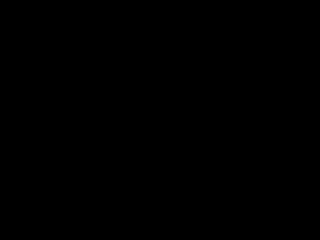

In [14]:
xml = """
<mujoco>
  <worldbody>
    <light name="top" pos="0 0 1"/>
    <geom name="red_box" type="box" size=".2 .2 .2" rgba="1 0 0 1"/>
    <geom name="green_sphere" pos=".2 .2 .2" size=".1" rgba="0 1 0 1"/>
  </worldbody>
</mujoco>
"""
# 모델(mjModel) 및 데이터(mjData) 생성
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# 렌더러를 생성하고 픽셀 이미지를 출력해 봅니다
renderer = mujoco.Renderer(model)
media.show_image(renderer.render())

""

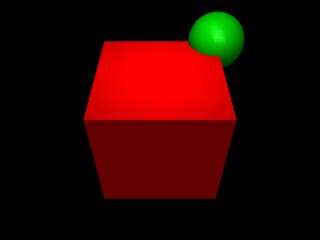

In [15]:
# mj_forward()를 호출하여 정기구학 및 동역학 파생 물리량을 계산한 뒤 씬을 업데이트합니다
mujoco.mj_forward(model, data)
renderer.update_scene(data)
media.show_image(renderer.render())

이제 정상적으로 보입니다! (`mj_forward`와 `renderer.update_scene(data)`를 호출하기 전에는 기하 위치가 전파되지 않아 검은 화면이나 원점에 겹친 상태로 렌더링됩니다.)

참고로 `mjModel` 인스턴스 내부의 값들도 코드에서 수정할 수 있습니다. 모델이 깨질 위험이 있는 구조적 파라미터는 XML에서 수정하는 것이 권장되지만, 색상(`rgba`)과 같은 시각적 속성은 실행 중에 실시간으로 안전하게 변경할 수 있습니다:

""

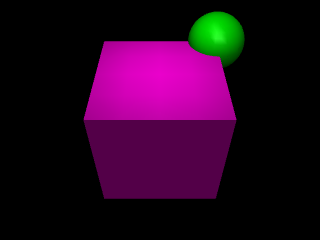

In [16]:
# 이 셀을 여러 번 실행하면 상자의 색상이 무작위로 바뀝니다
model.geom('red_box').rgba[:3] = np.random.rand(3)
renderer.update_scene(data)
media.show_image(renderer.render())

# 5. 물리 시뮬레이션 (`mj_step`)

이제 시간을 앞으로 진행시키며 시뮬레이션 비디오를 만들어 보겠습니다. MuJoCo의 가장 핵심적인 고수준 함수인 `mj_step`을 사용하며, 이는 상태 방정식 $x_{t+h} = f(x_t)$를 한 타임스텝($h$)만큼 적분합니다.

아래 코드에서 매 `mj_step` 호출마다 렌더링을 하지 않는 점에 주목하세요. 기본 물리 타임스텝은 `2ms`($500\text{Hz}$)이지만, 우리가 원하는 비디오는 $500\text{fps}$가 아니라 $60\text{fps}$이기 때문입니다.

In [17]:
duration = 3.8  # 시뮬레이션 시간 (초)
framerate = 60  # 비디오 프레임레이트 (Hz)

# 시뮬레이션 수행 및 비디오 출력
frames = []
mujoco.mj_resetData(model, data)  # 상태 및 시간을 초기값으로 리셋
while data.time < duration:
  mujoco.mj_step(model, data)
  if len(frames) < data.time * framerate:
    renderer.update_scene(data)
    pixels = renderer.render()
    frames.append(pixels)
media.show_video(frames, fps=framerate)

음, 비디오가 재생되지만 아무것도 움직이지 않습니다. 왜 그럴까요?

이 모델에는 **자유도([Degrees of Freedom, DoF](https://ko.wikipedia.org/wiki/%EC%9E%90%EC%9C%A0%EB%8F%84_(%EB%AC%BC%EB%A6%AC%ED%95%99)))**가 없기 때문입니다!
MuJoCo에서 실제로 움직이고 관성(inertia)을 가지는 단위는 **바디(`body`)**입니다. `<worldbody>`에 직접 선언된 `<geom>`은 바닥이나 벽처럼 월드에 고정된 정적 물체입니다.
물체가 움직이게 하려면 `<body>`를 만들고, 부모 바디에 대해 어떻게 움직일 수 있는지 정의하는 **관절(`joint`)**을 추가해야 합니다.

두 도형을 포함하는 `box_and_sphere` 바디를 만들고 회전 관절(`hinge joint`)을 추가한 뒤, 시각화 옵션 객체인 `MjvOption`을 사용해 관절 회전축까지 함께 표시해 보겠습니다.

In [18]:
try:
  del renderer
except:
  pass

xml = """
<mujoco>
  <worldbody>
    <light name="top" pos="0 0 1"/>
    <body name="box_and_sphere" euler="0 0 -30">
      <joint name="swing" type="hinge" axis="1 -1 0" pos="-.2 -.2 -.2"/>
      <geom name="red_box" type="box" size=".2 .2 .2" rgba="1 0 0 1"/>
      <geom name="green_sphere" pos=".2 .2 .2" size=".1" rgba="0 1 0 1"/>
    </body>
  </worldbody>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model)

# 관절(joint) 화살표 시각화 옵션 활성화:
scene_option = mujoco.MjvOption()
scene_option.flags[mujoco.mjtVisFlag.mjVIS_JOINT] = True

duration = 3.8  # (초)
framerate = 60  # (Hz)

frames = []
mujoco.mj_resetData(model, data)
while data.time < duration:
  mujoco.mj_step(model, data)
  if len(frames) < data.time * framerate:
    renderer.update_scene(data, scene_option=scene_option)
    pixels = renderer.render()
    frames.append(pixels)

# 시뮬레이션 비디오 재생
media.show_video(frames, fps=framerate)

This browser does not support the video tag.


위 XML에서 `euler="0 0 -30"` 속성을 통해 `box_and_sphere` 바디를 Z축(수직축) 기준으로 -30° 회전시킨 점에 주목하세요.
기구학 트리(kinematic tree) 내의 모든 자식 요소들의 위치와 자세는 항상 **부모 바디(parent body)에 대한 상대 좌표계**로 정의되므로, 내부의 두 `geom`과 `joint` 역시 함께 회전되었습니다.

시뮬레이션의 물리 옵션들은 `model.opt`에 저장되어 있습니다. 예를 들어 타임스텝(`timestep`) 크기를 확인해 보면 다음과 같습니다:

In [19]:
model.opt.timestep

0.002

이번에는 중력(`model.opt.gravity`) 방향을 반대로 뒤집어서(+Z 방향) 다시 시뮬레이션해 보겠습니다:

In [20]:
print('기본 중력 가속도:', model.opt.gravity)
model.opt.gravity = (0, 0, 10)
print('반전된 중력 가속도:', model.opt.gravity)

frames = []
mujoco.mj_resetData(model, data)
while data.time < duration:
  mujoco.mj_step(model, data)
  if len(frames) < data.time * framerate:
    renderer.update_scene(data, scene_option=scene_option)
    pixels = renderer.render()
    frames.append(pixels)

media.show_video(frames, fps=60)

default gravity [ 0.    0.   -9.81]
flipped gravity [ 0.  0. 10.]


This browser does not support the video tag.


### 자유도(Degrees of Freedom)와 일반화 좌표계 이해하기

현실 세계의 모든 3차원 강체(rigid body)는 3개의 이동(translation)과 3개의 회전(rotation)을 합쳐 총 6자유도(6-DoF)를 가집니다. 현실의 관절(joint)은 연결된 두 물체 사이의 상대적 움직임을 제한하는 **구속 조건(constraint)**으로 작용합니다. 일부 물리 엔진은 이러한 "직교 좌표계(Cartesian)" 또는 "차감식(subtractive)" 표현법을 사용하지만, 다관절 로봇 시뮬레이션에서는 계산 효율이 떨어지고 관절이 어긋나는 문제가 발생할 수 있습니다.

반면 **MuJoCo는 라그랑주 역학 기반의 "일반화 좌표계(Generalized coordinates)" 또는 "가산식(additive)" 표현법**을 사용합니다. 즉, 바디에 명시적으로 관절(`joint`)을 추가하지 않는 한 물체는 자유도를 가지지 않습니다.

현재 우리의 모델은 단일 힌지 관절(`hinge joint`) 하나만 가지고 있으므로 전체 자유도(`model.nv`)는 `1`이며, 시스템의 전체 상태는 오직 이 관절의 **각도(`qpos`)**와 **각속도(`qvel`)** 두 값만으로 완벽하게 정의됩니다:

In [21]:
print('모델의 총 자유도(DoF) 수:', model.nv)
print('일반화 위치 (qpos):', data.qpos)
print('일반화 속도 (qvel):', data.qvel)

Total number of DoFs in the model: 1
Generalized positions: [1.39239139]
Generalized velocities: [-3.79045972]


MuJoCo가 이처럼 일반화 좌표계를 사용하기 때문에, 렌더링을 하거나 물체의 전역 직교 좌표(`xpos`, `xmat`)를 읽기 전에 `mj_forward`나 `mj_kinematics`를 호출해야 하는 것입니다. 직교 좌표는 기본 상태가 아니라 일반화 위치(`qpos`)로부터 계산되는 파생 값이기 때문입니다.

# 6. 예제: 자유 물체(Free Body)와 스스로 뒤집히는 팽이 ("Tippe-Top")

**자유 물체(free body)**는 3차원 이동(3)과 회전(3)을 합쳐 6자유도(6-DoF)를 가지는 [`<freejoint/>`](https://mujoco.readthedocs.io/en/latest/XMLreference.html#body-freejoint)가 부여된 바디입니다.
단순히 상자를 떨어뜨리는 대신 훨씬 흥미로운 물리 현상을 시뮬레이션해 보겠습니다. **"티페 탑(Tippe top, 뒤집히는 팽이)"**은 빠르게 회전시키면 스스로 몸체를 뒤집어 손잡이(stem)로 서서 도는 신기한 장난감입니다([영상](https://www.youtube.com/watch?v=kbYpVrdcszQ), [위키백과](https://en.wikipedia.org/wiki/Tippe_top)). MJCF로 다음과 같이 모델링할 수 있습니다:

""

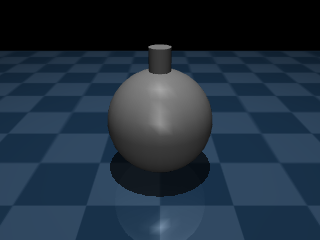

In [22]:
try:
  del renderer
except:
  pass

tippe_top = """
<mujoco model="tippe top">
  <option integrator="RK4"/>

  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1=".1 .2 .3"
     rgb2=".2 .3 .4" width="300" height="300"/>
    <material name="grid" texture="grid" texrepeat="8 8" reflectance=".2"/>
  </asset>

  <worldbody>
    <geom size=".2 .2 .01" type="plane" material="grid"/>
    <light pos="0 0 .6"/>
    <camera name="closeup" pos="0 -.1 .07" xyaxes="1 0 0 0 1 2"/>
    <body name="top" pos="0 0 .02">
      <freejoint/>
      <geom name="ball" type="sphere" size=".02" />
      <geom name="stem" type="cylinder" pos="0 0 .02" size="0.004 .008"/>
      <geom name="ballast" type="box" size=".023 .023 0.005"  pos="0 0 -.015"
       contype="0" conaffinity="0" group="3"/>
    </body>
  </worldbody>

  <keyframe>
    <key name="spinning" qpos="0 0 0.02 1 0 0 0" qvel="0 0 0 0 1 200" />
  </keyframe>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(tippe_top)
renderer = mujoco.Renderer(model)
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)
renderer.update_scene(data, camera="closeup")
media.show_image(renderer.render())

이 모델 정의에서 새롭게 등장한 주요 기능들을 살펴봅시다:
1. `<freejoint/>` 태그를 통해 6자유도(6-DoF) 자유 관절을 추가했습니다.
2. `<option/>` 태그에서 수치 적분기(integrator)를 기본 오일러(Euler) 방식 대신 4차 [룽게-쿠타(Runge-Kutta, `RK4`)](https://ko.wikipedia.org/wiki/%EB%A3%BD%EA%B2%8C-%EC%BF%A0%ED%83%80_%EB%B0%A9%EB%B2%95)로 설정했습니다. `RK4`는 동일한 타임스텝 크기에서 훨씬 높은 수렴 차수와 에너지 보존 정확도를 제공합니다.
3. `<asset/>` 태그 내부에 체크무늬 바닥 텍스처와 재질(`material="grid"`)을 정의하고 바닥 평면(`plane`)에서 참조했습니다.
4. 눈에 보이지 않고 충돌하지도 않는(`contype="0" conaffinity="0" group="3"`) 무거운 상자 `ballast`를 아래쪽에 배치하여 팽이의 무게중심(Center of Mass)을 낮추었습니다. (직관과 달리 무게중심이 구의 중심보다 낮아야 회전 중 뒤집히는 현상이 발생합니다.)
5. 초기 회전 상태를 `<keyframe>`으로 저장했습니다. Z축 방향의 높은 각속도(`200 rad/s`)와 함께 Y축으로 약간의 초기 각속도(`1 rad/s`)를 주어 대칭성을 깨뜨렸습니다(symmetry-breaking).
6. `<camera name="closeup">`을 모델에 정의하고 `update_scene(data, camera="closeup")`으로 해당 카메라 시점을 렌더링했습니다.

이제 초기 상태 벡터를 확인해 보겠습니다:

In [23]:
print('일반화 위치 (qpos, 길이 7):', data.qpos)
print('일반화 속도 (qvel, 길이 6):', data.qvel)

positions [0.   0.   0.02 1.   0.   0.   0.  ]
velocities [0. 0. 0. 0. 0. 0.]


속도(`qvel`)는 해석하기 쉽습니다. 6개의 자유도(선속도 3 + 각속도 3)에 대응하는 6개의 0입니다.
그렇다면 왜 위치(`qpos`)의 길이는 6이 아니라 **7**일까요?
- 앞의 3개 숫자 `0, 0, 0.02`는 바디의 3차원 위치 $(x, y, z)$ (초기 높이 $2\text{cm}$)를 나타냅니다.
- 뒤의 4개 숫자 `1, 0, 0, 0`은 짐벌락(Gimbal lock) 없는 3차원 자세 표현을 위한 **단위 쿼터니언(Unit Quaternion, $(w, x, y, z)$)**입니다!
즉, 3차원 공간에서 자세(orientation)는 4개의 숫자로 표현되는 반면, 각속도(angular velocity)는 3차원 벡터로 표현되기 때문에 `model.nq = 7`, `model.nv = 6`이 됩니다.

이제 키프레임 0번(`spinning`)으로 초기화한 뒤 7초간 시뮬레이션 영상을 만들어 보겠습니다:

In [24]:
duration = 7    # (초)
framerate = 60  # (Hz)

# 시뮬레이션 및 비디오 생성
frames = []
mujoco.mj_resetDataKeyframe(model, data, 0)  # 키프레임 0번('spinning') 상태로 리셋
while data.time < duration:
  mujoco.mj_step(model, data)
  if len(frames) < data.time * framerate:
    renderer.update_scene(data, "closeup")
    pixels = renderer.render()
    frames.append(pixels)

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


### `mjData`에서 물리량 계측 및 그래프 그리기
앞서 설명했듯 `mjData` 구조체는 시뮬레이션 매 스텝마다 변하는 동적 변수들과 계산 결과를 담고 있습니다.
아래에서는 시뮬레이션을 진행하면서 시간에 따른 **팽이의 3축 각속도(`data.qvel[3:6]`)**와 **손잡이(stem)의 높이(`data.geom_xpos[2, 2]`)**를 기록하여 그래프로 그려 보겠습니다.

In [25]:
data.body(1)

<_MjDataBodyViews
  cacc: array([0., 0., 0., 0., 0., 0.])
  cfrc_ext: array([0., 0., 0., 0., 0., 0.])
  cfrc_int: array([0., 0., 0., 0., 0., 0.])
  cinert: array([1.27362839e-05, 1.27373044e-05, 1.28282279e-05, 1.02176642e-09,
       7.64805200e-09, 1.23679721e-08, 1.92466076e-19, 0.00000000e+00,
       0.00000000e+00, 5.54745694e-02])
  crb: array([1.27362839e-05, 1.27373044e-05, 1.28282279e-05, 1.02176642e-09,
       7.64805200e-09, 1.23679721e-08, 1.92466076e-19, 0.00000000e+00,
       0.00000000e+00, 5.54745694e-02])
  cvel: array([ 3.93534372e-01,  2.89567118e+00,  8.17926078e+01,  2.52382030e-02,
        2.54512404e-02, -1.25879503e-03])
  id: 1
  name: 'top'
  subtree_angmom: array([0., 0., 0.])
  subtree_com: array([ 0.02377079, -0.02368274,  0.03328745])
  subtree_linvel: array([0., 0., 0.])
  xfrc_applied: array([0., 0., 0., 0., 0., 0.])
  ximat: array([-0.08161319, -0.50814533,  0.85739583, -0.13197997,  0.85819974,
        0.49605896, -0.98788692, -0.07267412, -0.13710543])

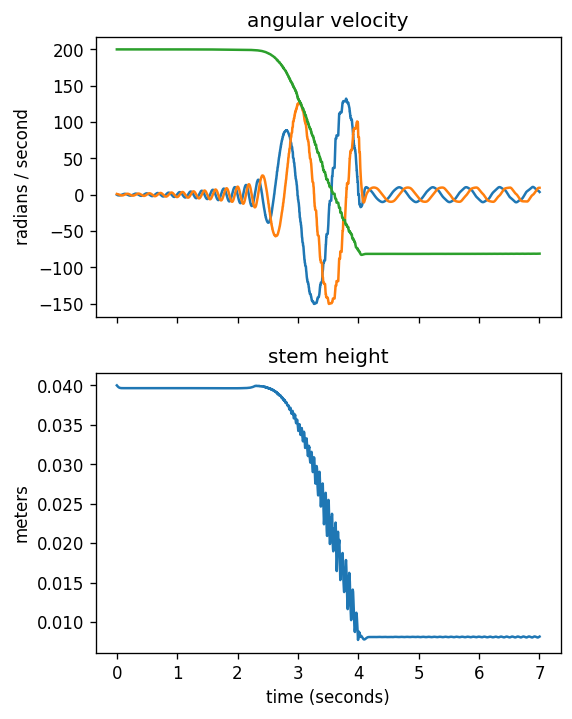

In [26]:
timevals = []
angular_velocity = []
stem_height = []

# 시뮬레이션 수행 및 데이터 기록
mujoco.mj_resetDataKeyframe(model, data, 0)
while data.time < duration:
  mujoco.mj_step(model, data)
  timevals.append(data.time)
  angular_velocity.append(data.qvel[3:6].copy())
  stem_height.append(data.geom_xpos[2, 2])

dpi = 120
width = 600
height = 800
figsize = (width / dpi, height / dpi)
_, ax = plt.subplots(2, 1, figsize=figsize, dpi=dpi, sharex=True)

ax[0].plot(timevals, angular_velocity)
ax[0].set_title('팽이의 각속도 (Angular Velocity)')
ax[0].set_ylabel('radians / second')
ax[0].legend(['wx', 'wy', 'wz'])

ax[1].plot(timevals, stem_height)
ax[1].set_xlabel('시간 (초)')
ax[1].set_ylabel('meters')
_ = ax[1].set_title('손잡이 높이 (Stem Height)')

# 7. 예제: 카오스 진자 (Chaotic Pendulum)
아래 모델은 샌프란시스코 과학관(Exploratorium)에 전시된 것과 유사한 [카오스 진자(다중 진자)](https://www.exploratorium.edu/exhibits/chaotic-pendulum) 모델입니다.
`<option>`에서 에너지 계산 플래그(`energy="enable"`)를 켜고 접촉 계산(`contact="disable"`)을 비활성화한 점에 주목하세요.

""

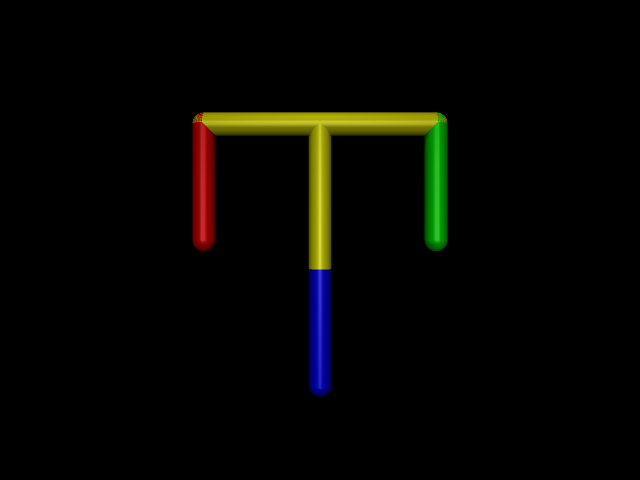

In [27]:
try:
  del renderer
except:
  pass

chaotic_pendulum = """
<mujoco>
  <option timestep=".001">
    <flag energy="enable" contact="disable"/>
  </option>

  <default>
    <joint type="hinge" axis="0 -1 0"/>
    <geom type="capsule" size=".02"/>
  </default>

  <worldbody>
    <light pos="0 -.4 1"/>
    <camera name="fixed" pos="0 -1 0" xyaxes="1 0 0 0 0 1"/>
    <body name="0" pos="0 0 .2">
      <joint name="root"/>
      <geom fromto="-.2 0 0 .2 0 0" rgba="1 1 0 1"/>
      <geom fromto="0 0 0 0 0 -.25" rgba="1 1 0 1"/>
      <body name="1" pos="-.2 0 0">
        <joint/>
        <geom fromto="0 0 0 0 0 -.2" rgba="1 0 0 1"/>
      </body>
      <body name="2" pos=".2 0 0">
        <joint/>
        <geom fromto="0 0 0 0 0 -.2" rgba="0 1 0 1"/>
      </body>
      <body name="3" pos="0 0 -.25">
        <joint/>
        <geom fromto="0 0 0 0 0 -.2" rgba="0 0 1 1"/>
      </body>
    </body>
  </worldbody>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(chaotic_pendulum)
renderer = mujoco.Renderer(model, 480, 640)
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)
renderer.update_scene(data, camera="fixed")
media.show_image(renderer.render())

## 시뮬레이션 속도 vs 렌더링 속도 측정 (Timing)
진자가 움직이는 영상을 만들면서, **물리 엔진 연산(`mj_step`)**과 **그래픽 렌더링(`render`)**에 각각 얼마나 시간이 걸리는지 측정해 보겠습니다:

In [28]:
try:
  del renderer
except:
  pass

# 설정
n_seconds = 6
framerate = 30  # Hz
n_frames = int(n_seconds * framerate)
frames = []
renderer = mujoco.Renderer(model, 240, 320)

# 초기 상태 설정 (뿌리 관절에 초기 각속도 10 rad/s 부여)
mujoco.mj_resetData(model, data)
data.joint('root').qvel = 10

# 시뮬레이션 및 프레임 기록 (시간 측정 포함)
frame = 0
sim_time = 0
render_time = 0
n_steps = 0
for i in range(n_frames):
  while data.time * framerate < i:
    tic = time.time()
    mujoco.mj_step(model, data)
    sim_time += time.time() - tic
    n_steps += 1
  tic = time.time()
  renderer.update_scene(data, "fixed")
  frame = renderer.render()
  render_time += time.time() - tic
  frames.append(frame)

# 측정 결과 출력 및 비디오 재생
step_time = 1e6 * sim_time / n_steps
step_fps = n_steps / max(sim_time, 1e-9)
print(f'물리 시뮬레이션: {step_time:5.3g} μs/step  ({step_fps:5.0f} Hz)')
frame_time = 1e6 * render_time / n_frames
frame_fps = n_frames / max(render_time, 1e-9)
print(f'화면 렌더링:     {frame_time:5.3g} μs/frame ({frame_fps:5.0f} Hz)')
print('\n')

media.show_video(frames, fps=framerate)

simulation:  2.39 μs/step  (417890Hz)
rendering:  1.87e+03 μs/frame (  535Hz)




This browser does not support the video tag.


결과에서 볼 수 있듯, **화면 렌더링은 물리 시뮬레이션 연산보다 수백~수천 배 더 느립니다.**
따라서 강화학습이나 대규모 최적화를 수행할 때는 학습 중 렌더링을 끄고 물리 스텝만 고속으로 돌린 뒤, 검증할 때만 렌더링을 수행합니다.

## 카오스 현상 (Chaos: 초기 조건에 대한 민감도)
이 다중 진자는 대표적인 **[카오스 시스템(Chaotic System)](https://ko.wikipedia.org/wiki/%ED%98%BC%EB%8F%88_%EC%9D%B4%EB%A1%A0)**입니다. 초기 속도에 $10^{-7}$ 수준의 아주 미세한 난수 섭동(perturbation)만 주어도 몇 초 뒤에는 궤적이 완전히 달라집니다:

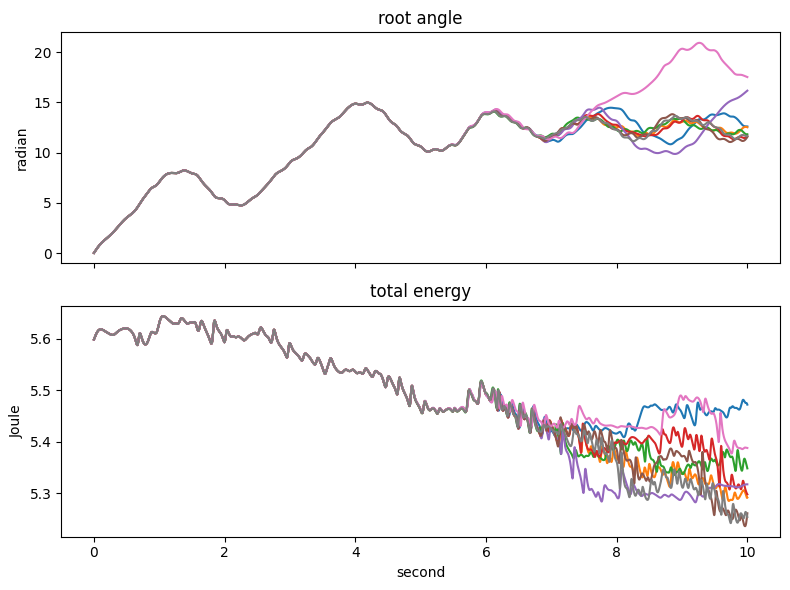

In [29]:
PERTURBATION = 1e-7
SIM_DURATION = 10 # 초
NUM_REPEATS = 8

# 배열 사전 할당
n_steps = int(SIM_DURATION / model.opt.timestep)
sim_time = np.zeros(n_steps)
angle = np.zeros(n_steps)
energy = np.zeros(n_steps)

# 그래프 축 준비
_, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# 아주 미세하게 다른 초기 조건으로 8번 반복 시뮬레이션
for _ in range(NUM_REPEATS):
  mujoco.mj_resetData(model, data)
  data.qvel[0] = 10 # root 관절 초기 각속도
  # 초기 속도에 1e-7 크기의 미세한 섭동 추가
  data.qvel[:] += PERTURBATION * np.random.randn(model.nv)

  for i in range(n_steps):
    mujoco.mj_step(model, data)
    sim_time[i] = data.time
    angle[i] = data.joint('root').qpos[0]
    energy[i] = data.energy[0] + data.energy[1] # 위치 에너지 + 운동 에너지

  ax[0].plot(sim_time, angle)
  ax[1].plot(sim_time, energy)

ax[0].set_title('뿌리 관절 각도 (Root Angle)')
ax[0].set_ylabel('radian')
ax[1].set_title('총 역학적 에너지 (Total Energy)')
ax[1].set_ylabel('Joule')
ax[1].set_xlabel('second')
plt.tight_layout()

## 타임스텝 크기와 정확도 (Timestep and Accuracy)
**질문:** 위 그래프에서 마찰이나 감쇠(damping)가 전혀 없는데도 왜 총 에너지(`total energy`)가 시간에 따라 조금씩 변할까요? 이론적으로 역학적 에너지는 일정하게 보존되어야 하지 않나요?

**답변:** **시간의 이산화(Discretization of time)**에 따른 수치 적분 오차 때문입니다.

타임스텝(`model.opt.timestep`)을 $10\text{ms}$에서 $0.1\text{ms}$까지 줄여가며 시뮬레이션하면, 타임스텝이 작아질수록 수치 정확도가 높아져 에너지가 거의 완벽하게 보존되는 것을 확인할 수 있습니다:

1000 steps at dt = 10ms
3162 steps at dt = 3.2ms
10000 steps at dt =  1ms
31622 steps at dt = 0.32ms
100000 steps at dt = 0.1ms


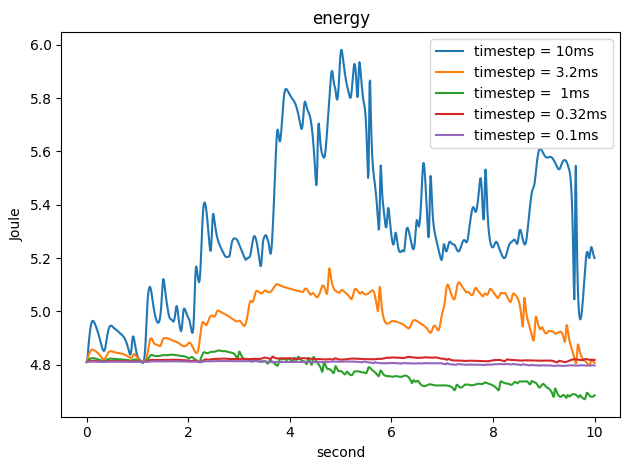

In [30]:
SIM_DURATION = 10 # (seconds)
TIMESTEPS = np.power(10, np.linspace(-2, -4, 5))

# prepare plotting axes
_, ax = plt.subplots(1, 1)

for dt in TIMESTEPS:
   # set timestep, print
  model.opt.timestep = dt

  # allocate
  n_steps = int(SIM_DURATION / model.opt.timestep)
  sim_time = np.zeros(n_steps)
  energy = np.zeros(n_steps)

  # initialize
  mujoco.mj_resetData(model, data)
  data.qvel[0] = 9 # root joint velocity

  # simulate
  print('{} steps at dt = {:2.2g}ms'.format(n_steps, 1000*dt))
  for i in range(n_steps):
    mujoco.mj_step(model, data)
    sim_time[i] = data.time
    energy[i] = data.energy[0] + data.energy[1]

  # plot
  ax.plot(sim_time, energy, label='timestep = {:2.2g}ms'.format(1000*dt))

# finalize plot
ax.set_title('energy')
ax.set_ylabel('Joule')
ax.set_xlabel('second')
ax.legend(frameon=True);
plt.tight_layout()

## 타임스텝 크기와 수치 발산 (Timestep and Divergence)
반대로 타임스텝을 너무 크게 늘리면 어떻게 될까요? 오차가 급격히 누적되면서 시뮬레이션이 **발산(Divergence)**하여 폭주하게 됩니다. MuJoCo는 발산을 감지하면 `data.warning`에 경고를 기록합니다:

simulating 1000 steps at dt = 10ms

stopped due to divergence (mjWARN_BADQACC) at timestep 385.

simulating 825 steps at dt = 12ms

stopped due to divergence (mjWARN_BADQACC) at timestep 322.

simulating 681 steps at dt = 15ms

stopped due to divergence (mjWARN_BADQACC) at timestep 166.

simulating 562 steps at dt = 18ms

stopped due to divergence (mjWARN_BADQACC) at timestep 105.

simulating 464 steps at dt = 22ms

stopped due to divergence (mjWARN_BADQACC) at timestep 84.

simulating 383 steps at dt = 26ms

stopped due to divergence (mjWARN_BADQACC) at timestep 61.

simulating 316 steps at dt = 32ms

stopped due to divergence (mjWARN_BADQACC) at timestep 45.



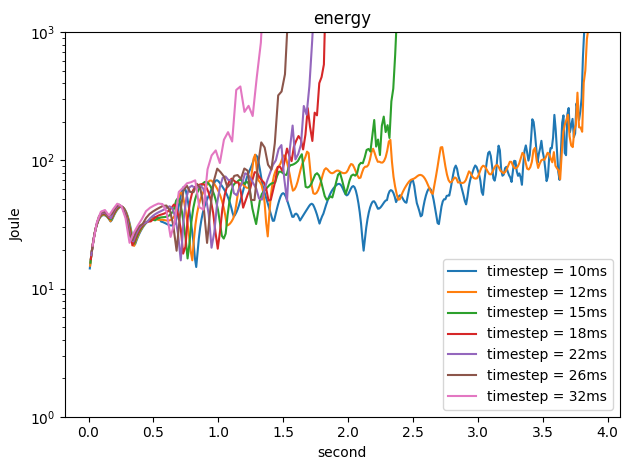

In [31]:
SIM_DURATION = 10 # (seconds)
TIMESTEPS = np.power(10, np.linspace(-2, -1.5, 7))

# get plotting axes
ax = plt.gca()

for dt in TIMESTEPS:
  # set timestep
  model.opt.timestep = dt

  # allocate
  n_steps = int(SIM_DURATION / model.opt.timestep)
  sim_time = np.zeros(n_steps)
  energy = np.zeros(n_steps) * np.nan
  speed = np.zeros(n_steps) * np.nan

  # initialize
  mujoco.mj_resetData(model, data)
  data.qvel[0] = 11 # set root joint velocity

  # simulate
  print('simulating {} steps at dt = {:2.2g}ms'.format(n_steps, 1000*dt))
  for i in range(n_steps):
    mujoco.mj_step(model, data)
    if data.warning.number.any():
      warning_index = np.nonzero(data.warning.number)[0][0]
      warning = mujoco.mjtWarning(warning_index).name
      print(f'stopped due to divergence ({warning}) at timestep {i}.\n')
      break
    sim_time[i] = data.time
    energy[i] = sum(abs(data.qvel))
    speed[i] = np.linalg.norm(data.qvel)

  # plot
  ax.plot(sim_time, energy, label='timestep = {:2.2g}ms'.format(1000*dt))
  ax.set_yscale('log')


# finalize plot
ax.set_ybound(1, 1e3)
ax.set_title('energy')
ax.set_ylabel('Joule')
ax.set_xlabel('second')
ax.legend(frameon=True, loc='lower right');
plt.tight_layout()

# 8. 접촉 역학 (Contacts) 및 마찰 (Friction)

이제 처음에 보았던 상자와 구(`box_and_sphere`) 모델에 6자유도 자유 관절(`<freejoint/>`)과 바닥 평면(`ground`)을 추가하여 바닥과의 충돌 및 접촉 역학을 살펴보겠습니다:

""

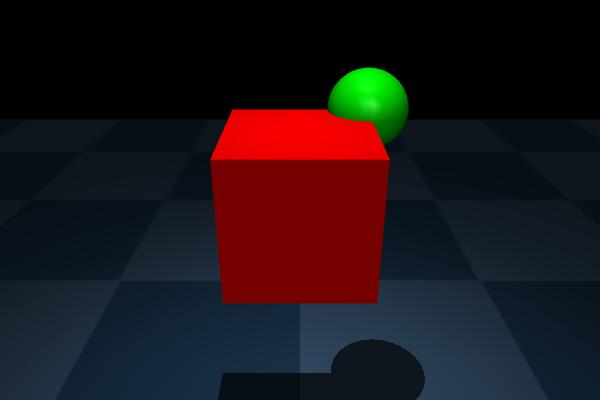

In [32]:
try:
  del renderer
except:
  pass

free_body_MJCF = """
<mujoco>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1=".1 .2 .3"
    rgb2=".2 .3 .4" width="300" height="300" mark="edge" markrgb=".2 .3 .4"/>
    <material name="grid" texture="grid" texrepeat="2 2" texuniform="true"
    reflectance=".2"/>
  </asset>

  <worldbody>
    <light pos="0 0 1" mode="trackcom"/>
    <geom name="ground" type="plane" pos="0 0 -.5" size="2 2 .1" material="grid" solimp=".99 .99 .01" solref=".001 1"/>
    <body name="box_and_sphere" pos="0 0 0">
      <freejoint/>
      <geom name="red_box" type="box" size=".1 .1 .1" rgba="1 0 0 1" solimp=".99 .99 .01"  solref=".001 1"/>
      <geom name="green_sphere" size=".06" pos=".1 .1 .1" rgba="0 1 0 1"/>
      <camera name="fixed" pos="0 -.6 .3" xyaxes="1 0 0 0 1 2"/>
      <camera name="track" pos="0 -.6 .3" xyaxes="1 0 0 0 1 2" mode="track"/>
    </body>
  </worldbody>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(free_body_MJCF)
renderer = mujoco.Renderer(model, 400, 600)
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)
renderer.update_scene(data, "fixed")
media.show_image(renderer.render())

물체에 무작위 초기 회전 속도를 주고 바닥에 떨어뜨려 굴러가는 모습을 **1/4배속 슬로우 모션**으로 렌더링해 보겠습니다.
이때 `MjvOption`을 사용해 **접촉점(`mjVIS_CONTACTPOINT`)**과 **접촉력 벡터(`mjVIS_CONTACTFORCE`)**를 시각화하고, 물체를 반투명(`mjVIS_TRANSPARENT`)하게 만들어 내부에서 작용하는 힘까지 관찰합니다:

In [33]:
try:
  del renderer
except:
  pass

n_frames = 200
height = 240
width = 320
frames = []
renderer = mujoco.Renderer(model, height, width)

# visualize contact frames and forces, make body transparent
options = mujoco.MjvOption()
mujoco.mjv_defaultOption(options)
options.flags[mujoco.mjtVisFlag.mjVIS_CONTACTPOINT] = True
options.flags[mujoco.mjtVisFlag.mjVIS_CONTACTFORCE] = True
options.flags[mujoco.mjtVisFlag.mjVIS_TRANSPARENT] = True

# tweak scales of contact visualization elements
model.vis.scale.contactwidth = 0.1
model.vis.scale.contactheight = 0.03
model.vis.scale.forcewidth = 0.05
model.vis.map.force = 0.3

# random initial rotational velocity:
mujoco.mj_resetData(model, data)
data.qvel[3:6] = 5*np.random.randn(3)

# simulate and render
for i in range(n_frames):
  while data.time < i/120.0: #1/4x real time
    mujoco.mj_step(model, data)
  renderer.update_scene(data, "track", options)
  frame = renderer.render()
  frames.append(frame)

# show video
media.show_video(frames, fps=30)

This browser does not support the video tag.


## 접촉력 정밀 분석 (Analysis of Contact Forces)

위 시뮬레이션을 다시 실행하면서 매 스텝마다 발생하는 접촉 관련 물리량(접촉점 개수 `data.ncon`, 접촉력 `mj_contactForce`, 가속도, 속도, 바닥 침투 깊이 `c.dist`)을 기록하여 그래프로 분석해 보겠습니다:

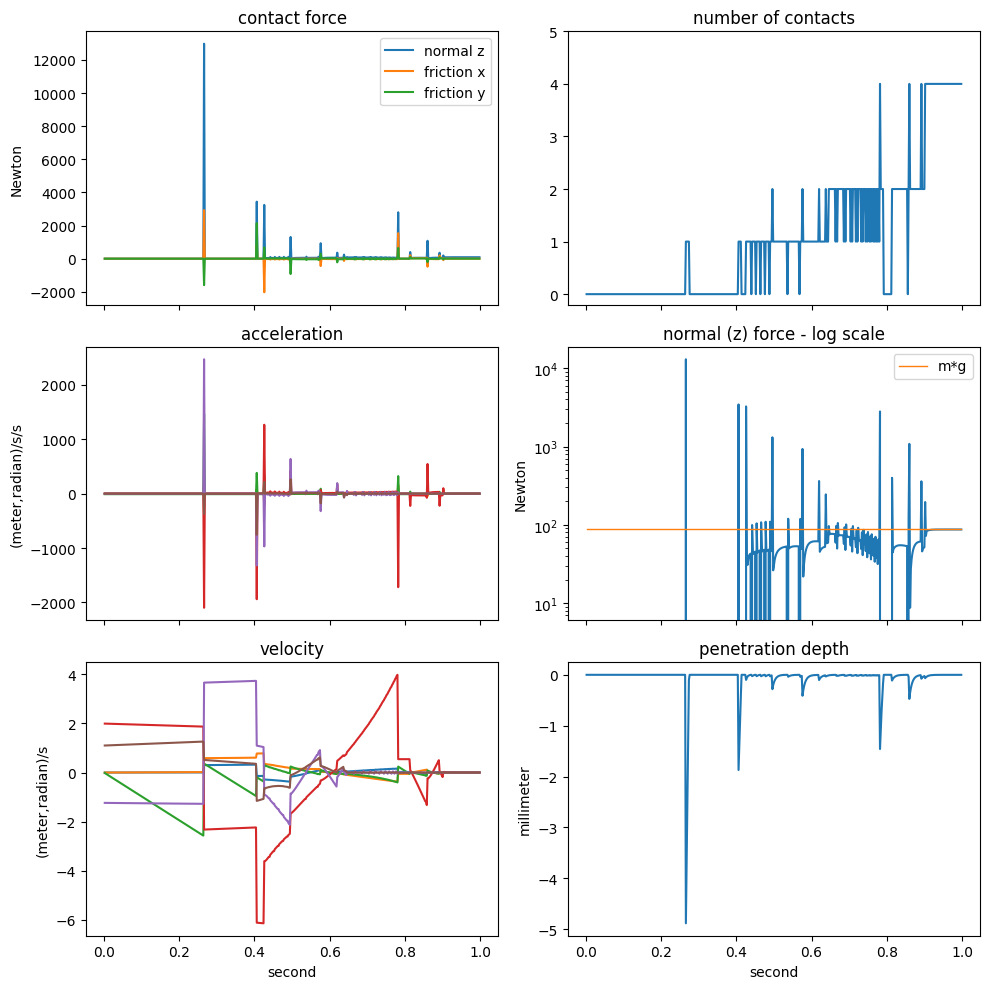

In [34]:
n_steps = 499

# allocate
sim_time = np.zeros(n_steps)
ncon = np.zeros(n_steps)
force = np.zeros((n_steps,3))
velocity = np.zeros((n_steps, model.nv))
penetration = np.zeros(n_steps)
acceleration = np.zeros((n_steps, model.nv))
forcetorque = np.zeros(6)

# random initial rotational velocity:
mujoco.mj_resetData(model, data)
data.qvel[3:6] = 2*np.random.randn(3)

# simulate and save data
for i in range(n_steps):
  mujoco.mj_step(model, data)
  sim_time[i] = data.time
  ncon[i] = data.ncon
  velocity[i] = data.qvel[:]
  acceleration[i] = data.qacc[:]
  # iterate over active contacts, save force and distance
  for j,c in enumerate(data.contact):
    mujoco.mj_contactForce(model, data, j, forcetorque)
    force[i] += forcetorque[0:3]
    penetration[i] = min(penetration[i], c.dist)
  # we could also do
  # force[i] += data.qfrc_constraint[0:3]
  # do you see why?

# plot
_, ax = plt.subplots(3, 2, sharex=True, figsize=(10, 10))

lines = ax[0,0].plot(sim_time, force)
ax[0,0].set_title('contact force')
ax[0,0].set_ylabel('Newton')
ax[0,0].legend(iter(lines), ('normal z', 'friction x', 'friction y'));

ax[1,0].plot(sim_time, acceleration)
ax[1,0].set_title('acceleration')
ax[1,0].set_ylabel('(meter,radian)/s/s')

ax[2,0].plot(sim_time, velocity)
ax[2,0].set_title('velocity')
ax[2,0].set_ylabel('(meter,radian)/s')
ax[2,0].set_xlabel('second')

ax[0,1].plot(sim_time, ncon)
ax[0,1].set_title('number of contacts')
ax[0,1].set_yticks(range(6))

ax[1,1].plot(sim_time, force[:,0])
ax[1,1].set_yscale('log')
ax[1,1].set_title('normal (z) force - log scale')
ax[1,1].set_ylabel('Newton')
z_gravity = -model.opt.gravity[2]
mg = model.body("box_and_sphere").mass[0] * z_gravity
mg_line = ax[1,1].plot(sim_time, np.ones(n_steps)*mg, label='m*g', linewidth=1)
ax[1,1].legend()

ax[2,1].plot(sim_time, 1000*penetration)
ax[2,1].set_title('penetration depth')
ax[2,1].set_ylabel('millimeter')
ax[2,1].set_xlabel('second')

plt.tight_layout()

## 마찰 계수의 영향 (Friction)

경사진 바닥 위에 마찰 계수(`friction`)가 서로 다른 두 개의 상자(`0.1` vs `0.33`)를 놓았을 때 미끄러지는 속도의 차이를 확인해 보겠습니다:

In [35]:
try:
  del renderer
except:
  pass

MJCF = """
<mujoco>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1=".1 .2 .3"
     rgb2=".2 .3 .4" width="300" height="300" mark="none"/>
    <material name="grid" texture="grid" texrepeat="6 6"
     texuniform="true" reflectance=".2"/>
     <material name="wall" rgba='.5 .5 .5 1'/>
  </asset>

  <default>
    <geom type="box" size=".05 .05 .05" />
    <joint type="free"/>
  </default>

  <worldbody>
    <light name="light" pos="-.2 0 1"/>
    <geom name="ground" type="plane" size=".5 .5 10" material="grid"
     zaxis="-.3 0 1" friction=".1"/>
    <camera name="y" pos="-.1 -.6 .3" xyaxes="1 0 0 0 1 2"/>
    <body pos="0 0 .1">
      <joint/>
      <geom/>
    </body>
    <body pos="0 .2 .1">
      <joint/>
      <geom friction=".33"/>
    </body>
  </worldbody>

</mujoco>
"""
n_frames = 60
height = 300
width = 300
frames = []

# load
model = mujoco.MjModel.from_xml_string(MJCF)
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, height, width)

# simulate and render
mujoco.mj_resetData(model, data)
for i in range(n_frames):
  while data.time < i/30.0:
    mujoco.mj_step(model, data)
  renderer.update_scene(data, "y")
  frame = renderer.render()
  frames.append(frame)
media.show_video(frames, fps=30)

This browser does not support the video tag.


# 9. 힘줄(Tendons), 액추에이터(Actuators) 및 센서(Sensors)

MuJoCo는 강체와 관절뿐만 아니라 다음과 같은 풍부한 로보틱스 요소를 지원합니다:
- **`<tendon>` (힘줄/와이어)**: 두 지점(`site`)을 연결하여 최대 길이를 제한하는 줄(끈)이나 근육 모델을 정의합니다.
- **`<actuator>` (구동기/모터)**: 관절이나 힘줄에 토크, 힘, 위치/속도 명령(`data.ctrl`)을 가합니다.
- **`<sensor>` (센서)**: IMU(가속도계, 자이로스코프), 힘/토크 센서, 관절 엔코더 등의 측정값을 `data.sensordata`에 기록합니다.

아래 예제는 천장에 매달린 상자(피냐타, piñata)를 모터로 회전하는 방망이(`bat`)로 타격하고, 상자 내부에 부착된 **가속도계 센서(`accelerometer`)**로 충격 가속도를 측정하는 시뮬레이션입니다:

""

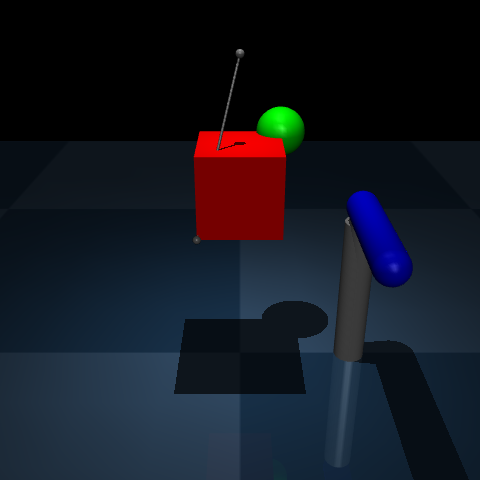

In [36]:
try:
  del renderer
except:
  pass

MJCF = """
<mujoco>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1=".1 .2 .3"
     rgb2=".2 .3 .4" width="300" height="300" mark="none"/>
    <material name="grid" texture="grid" texrepeat="1 1"
     texuniform="true" reflectance=".2"/>
  </asset>

  <worldbody>
    <light name="light" pos="0 0 1"/>
    <geom name="floor" type="plane" pos="0 0 -.5" size="2 2 .1" material="grid"/>
    <site name="anchor" pos="0 0 .3" size=".01"/>
    <camera name="fixed" pos="0 -1.3 .5" xyaxes="1 0 0 0 1 2"/>

    <geom name="pole" type="cylinder" fromto=".3 0 -.5 .3 0 -.1" size=".04"/>
    <body name="bat" pos=".3 0 -.1">
      <joint name="swing" type="hinge" damping="1" axis="0 0 1"/>
      <geom name="bat" type="capsule" fromto="0 0 .04 0 -.3 .04"
       size=".04" rgba="0 0 1 1"/>
    </body>

    <body name="box_and_sphere" pos="0 0 0">
      <joint name="free" type="free"/>
      <geom name="red_box" type="box" size=".1 .1 .1" rgba="1 0 0 1"/>
      <geom name="green_sphere"  size=".06" pos=".1 .1 .1" rgba="0 1 0 1"/>
      <site name="hook" pos="-.1 -.1 -.1" size=".01"/>
      <site name="IMU"/>
    </body>
  </worldbody>

  <tendon>
    <spatial name="wire" limited="true" range="0 0.35" width="0.003">
      <site site="anchor"/>
      <site site="hook"/>
    </spatial>
  </tendon>

  <actuator>
    <motor name="my_motor" joint="swing" gear="1"/>
  </actuator>

  <sensor>
    <accelerometer name="accelerometer" site="IMU"/>
  </sensor>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(MJCF)
renderer = mujoco.Renderer(model, 480, 480)
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)
renderer.update_scene(data, "fixed")
media.show_image(renderer.render())

모터에 일정한 제어 입력(`data.ctrl = 20`)을 가하여 회전하는 방망이와 줄에 매달린 상자의 움직임을 시뮬레이션합니다:

In [37]:
try:
  del renderer
except:
  pass

n_frames = 180
height = 240
width = 320
frames = []
fps = 60.0
times = []
sensordata = []

renderer = mujoco.Renderer(model, height, width)

# constant actuator signal
mujoco.mj_resetData(model, data)
data.ctrl = 20

# simulate and render
for i in range(n_frames):
  while data.time < i/fps:
    mujoco.mj_step(model, data)
    times.append(data.time)
    sensordata.append(data.sensor('accelerometer').data.copy())
  renderer.update_scene(data, "fixed")
  frame = renderer.render()
  frames.append(frame)

media.show_video(frames, fps=fps)

This browser does not support the video tag.


이제 상자 내부의 가속도계 센서(`accelerometer`)가 측정한 시간에 따른 3축 가속도 값을 그래프로 그려 보겠습니다:

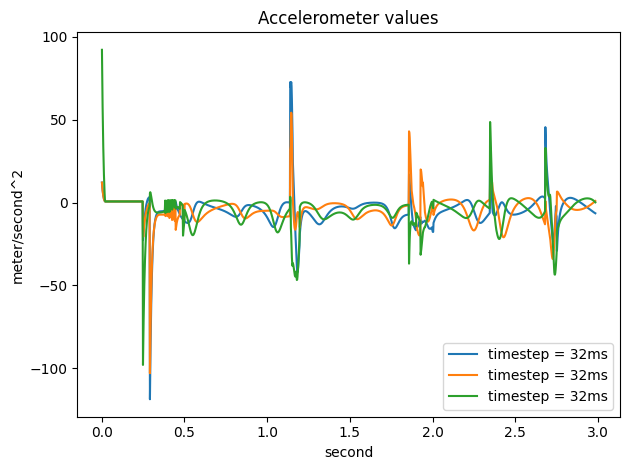

In [38]:
_, ax = plt.subplots(1, 1, figsize=(8, 4))

ax.plot(np.asarray(times), np.asarray(sensordata), label='timestep = {:2.2g}ms'.format(1000*model.opt.timestep))

# 그래프 마무리
ax.set_title('가속도계 센서 측정값 (Accelerometer Values)')
ax.set_ylabel('meter/second^2')
ax.set_xlabel('second')
ax.legend(['ax', 'ay', 'az'], frameon=True, loc='lower right')
plt.tight_layout()

방망이가 상자를 타격하는 순간마다 가속도계 측정값에 날카로운 충격 스파이크(spike)가 명확하게 나타나는 것을 볼 수 있습니다!

# 10. 고급 렌더링 및 컴퓨터 비전 기능 (Advanced Rendering)

로봇 비전(Robot Vision)이나 강화학습에서는 RGB 카메라 이미지뿐만 아니라 **깊이 이미지(Depth image)**, **객체 분할 마스크(Segmentation mask)**, 그리고 **카메라 투영 행렬(Camera Matrix)**이 자주 필요합니다.
처음에 만들었던 모델을 다시 불러와 이 기능들을 실습해 보겠습니다:

""

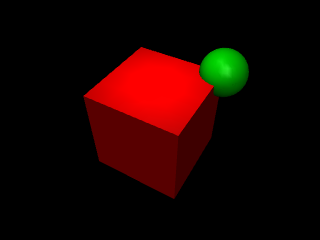

In [39]:
try:
  del renderer
except:
  pass

xml = """
<mujoco>
  <worldbody>
    <light name="top" pos="0 0 1"/>
    <body name="box_and_sphere" euler="0 0 -30">
      <joint name="swing" type="hinge" axis="1 -1 0" pos="-.2 -.2 -.2"/>
      <geom name="red_box" type="box" size=".2 .2 .2" rgba="1 0 0 1"/>
      <geom name="green_sphere" pos=".2 .2 .2" size=".1" rgba="0 1 0 1"/>
    </body>
  </worldbody>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(xml)
renderer = mujoco.Renderer(model)
data = mujoco.MjData(model)

mujoco.mj_forward(model, data)
renderer.update_scene(data)
media.show_image(renderer.render())

## 투명도 및 지역 좌표계(Frame) 시각화 활성화
`scene_option.frame = mujoco.mjtFrame.mjFRAME_GEOM`을 설정하면 각 기하 물체의 로컬 좌표축(빨강=X, 초록=Y, 파랑=Z)을 화면에 표시할 수 있습니다:

""

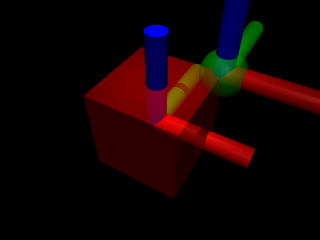

In [40]:
scene_option = mujoco.MjvOption()
scene_option.frame = mujoco.mjtFrame.mjFRAME_GEOM
scene_option.flags[mujoco.mjtVisFlag.mjVIS_TRANSPARENT] = True
renderer.update_scene(data, scene_option=scene_option)
frame = renderer.render()
media.show_image(frame)

## 깊이 렌더링 (Depth Rendering)
`renderer.enable_depth_rendering()`을 호출하면 `renderer.render()`가 픽셀별 카메라 거리(단위: 미터, `float` 배열)를 반환합니다. 이를 `[0, 255]` 범위로 정규화하여 시각화해 보겠습니다:

""

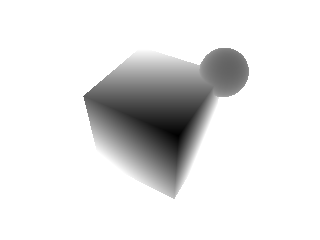

In [41]:
# update renderer to render depth
renderer.enable_depth_rendering()

# reset the scene
renderer.update_scene(data)

# depth is a float array, in meters.
depth = renderer.render()

# Shift nearest values to the origin.
depth -= depth.min()
# Scale by 2 mean distances of near rays.
depth /= 2*depth[depth <= 1].mean()
# Scale to [0, 255]
pixels = 255*np.clip(depth, 0, 1)

media.show_image(pixels.astype(np.uint8))

renderer.disable_depth_rendering()

## 세그멘테이션 렌더링 (Segmentation Rendering)
`renderer.enable_segmentation_rendering()`을 호출하면 각 픽셀이 어떤 객체(`geom ID`)에 속하는지 나타내는 정수 ID 맵을 얻을 수 있습니다:

""

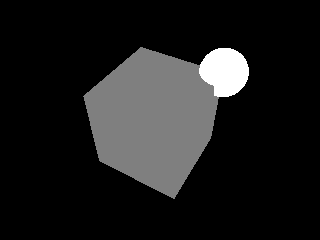

In [42]:
# update renderer to render segmentation
renderer.enable_segmentation_rendering()

# reset the scene
renderer.update_scene(data)

seg = renderer.render()

# Display the contents of the first channel, which contains object
# IDs. The second channel, seg[:, :, 1], contains object types.
geom_ids = seg[:, :, 0]
# Infinity is mapped to -1
geom_ids = geom_ids.astype(np.float64) + 1
# Scale to [0, 1]
geom_ids = geom_ids / geom_ids.max()
pixels = 255*geom_ids
media.show_image(pixels.astype(np.uint8))

renderer.disable_segmentation_rendering()

### 카메라 투영 행렬 (The Camera Matrix)

3차원 월드 좌표 $(X, Y, Z)$를 2차원 카메라 이미지의 픽셀 좌표 $(u, v)$로 변환하는 $3 \times 4$ **[카메라 행렬(Camera Matrix)](https://en.wikipedia.org/wiki/Camera_matrix)**을 계산하는 함수를 정의해 보겠습니다:

In [43]:
def compute_camera_matrix(renderer, data):
  """Returns the 3x4 camera matrix."""
  # If the camera is a 'free' camera, we get its position and orientation
  # from the scene data structure. It is a stereo camera, so we average over
  # the left and right channels. Note: we call `self.update()` in order to
  # ensure that the contents of `scene.camera` are correct.
  renderer.update_scene(data)
  pos = np.mean([camera.pos for camera in renderer.scene.camera], axis=0)
  z = -np.mean([camera.forward for camera in renderer.scene.camera], axis=0)
  y = np.mean([camera.up for camera in renderer.scene.camera], axis=0)
  rot = np.vstack((np.cross(y, z), y, z))
  fov = model.vis.global_.fovy

  # Translation matrix (4x4).
  translation = np.eye(4)
  translation[0:3, 3] = -pos

  # Rotation matrix (4x4).
  rotation = np.eye(4)
  rotation[0:3, 0:3] = rot

  # Focal transformation matrix (3x4).
  focal_scaling = (1./np.tan(np.deg2rad(fov)/2)) * renderer.height / 2.0
  focal = np.diag([-focal_scaling, focal_scaling, 1.0, 0])[0:3, :]

  # Image matrix (3x3).
  image = np.eye(3)
  image[0, 2] = (renderer.width - 1) / 2.0
  image[1, 2] = (renderer.height - 1) / 2.0
  return image @ focal @ rotation @ translation

## 3차원 월드 좌표를 2차원 카메라 픽셀 좌표로 투영하기
위에서 정의한 카메라 행렬을 이용해 빨간 상자(`red_box`)의 8개 꼭짓점(corners)의 3차원 월드 좌표를 계산하고, 이를 이미지 픽셀 좌표계로 투영하여 흰색 `+` 마커로 겹쳐 그려 보겠습니다:

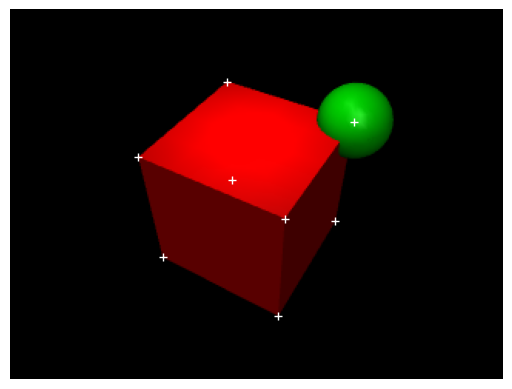

In [44]:
# reset the scene
renderer.update_scene(data)


# Get the world coordinates of the box corners
box_pos = data.geom_xpos[model.geom('red_box').id]
box_mat = data.geom_xmat[model.geom('red_box').id].reshape(3, 3)
box_size = model.geom_size[model.geom('red_box').id]
offsets = np.array([-1, 1]) * box_size[:, None]
xyz_local = np.stack(list(itertools.product(*offsets))).T
xyz_global = box_pos[:, None] + box_mat @ xyz_local

# Camera matrices multiply homogenous [x, y, z, 1] vectors.
corners_homogeneous = np.ones((4, xyz_global.shape[1]), dtype=float)
corners_homogeneous[:3, :] = xyz_global

# Get the camera matrix.
m = compute_camera_matrix(renderer, data)

# Project world coordinates into pixel space. See:
# https://en.wikipedia.org/wiki/3D_projection#Mathematical_formula
xs, ys, s = m @ corners_homogeneous
# x and y are in the pixel coordinate system.
x = xs / s
y = ys / s

# Render the camera view and overlay the projected corner coordinates.
pixels = renderer.render()
fig, ax = plt.subplots(1, 1)
ax.imshow(pixels)
ax.plot(x, y, '+', c='w')
ax.set_axis_off()

## 씬(Scene)에 사용자 정의 기하 요소 추가하기 (`mjvScene` 수정)

로봇의 이동 궤적(trajectory), 목표 지점, 힘 벡터 등 물리 시뮬레이션에는 영향을 주지 않는 순수 시각적 요소들을 `renderer.scene`(`mjvScene`)에 동적으로 추가할 수 있습니다.
아래 코드는 초록색 구(`green_sphere`)의 이동 경로와 속력을 추적하여, 속력에 따라 색상과 굵기가 변하는 캡슐(capsule) 궤적 잔상을 3차원 공간에 그립니다:

In [45]:
def get_geom_speed(model, data, geom_name):
  """Returns the speed of a geom."""
  geom_vel = np.zeros(6)
  geom_type = mujoco.mjtObj.mjOBJ_GEOM
  geom_id = data.geom(geom_name).id
  mujoco.mj_objectVelocity(model, data, geom_type, geom_id, geom_vel, 0)
  return np.linalg.norm(geom_vel)

def add_visual_capsule(scene, point1, point2, radius, rgba):
  """Adds one capsule to an mjvScene."""
  if scene.ngeom >= scene.maxgeom:
    return
  scene.ngeom += 1  # increment ngeom
  # initialise a new capsule, add it to the scene using mjv_makeConnector
  mujoco.mjv_initGeom(scene.geoms[scene.ngeom-1],
                      mujoco.mjtGeom.mjGEOM_CAPSULE, np.zeros(3),
                      np.zeros(3), np.zeros(9), rgba.astype(np.float32))
  mujoco.mjv_makeConnector(scene.geoms[scene.ngeom-1],
                           mujoco.mjtGeom.mjGEOM_CAPSULE, radius,
                           point1[0], point1[1], point1[2],
                           point2[0], point2[1], point2[2])

 # traces of time, position and speed
times = []
positions = []
speeds = []
offset = model.jnt_axis[0]/16  # offset along the joint axis

def modify_scene(scn):
  """Draw position trace, speed modifies width and colors."""
  if len(positions) > 1:
    for i in range(len(positions)-1):
      rgba=np.array((np.clip(speeds[i]/10, 0, 1),
                     np.clip(1-speeds[i]/10, 0, 1),
                     .5, 1.))
      radius=.003*(1+speeds[i])
      point1 = positions[i] + offset*times[i]
      point2 = positions[i+1] + offset*times[i+1]
      add_visual_capsule(scn, point1, point2, radius, rgba)

duration = 6    # (seconds)
framerate = 30  # (Hz)

# Simulate and display video.
frames = []

# Reset state and time.
mujoco.mj_resetData(model, data)
mujoco.mj_forward(model, data)

while data.time < duration:
  # append data to the traces
  positions.append(data.geom_xpos[data.geom("green_sphere").id].copy())
  times.append(data.time)
  speeds.append(get_geom_speed(model, data, "green_sphere"))
  mujoco.mj_step(model, data)
  if len(frames) < data.time * framerate:
    renderer.update_scene(data)
    modify_scene(renderer.scene)
    pixels = renderer.render()
    frames.append(pixels)
media.show_video(frames, fps=framerate)

This browser does not support the video tag.


## 11. 종합 예제: 도미노 시뮬레이션과 동적 카메라 제어 (Camera Control)

마지막으로 경사로를 구르는 공이 점점 커지는 도미노들을 쓰러뜨리고, 마지막 도미노가 시소(seesaw)를 때려 작은 상자를 공중으로 날려 보내는 **도미노 시뮬레이션**을 만들어 보겠습니다.

또한 카메라를 고정해 두는 것뿐만 아니라, 시뮬레이션 상황에 맞춰 **전체 궤도를 도는 카메라(Orbit motion)**에서 **날아가는 상자를 추적하는 카메라(Track motion)**로 부드럽게 전환하는 시네마틱 카메라 워킹을 구현합니다.

### 도미노("dominos") 모델 불러오기

In [46]:
try:
  del renderer
except:
  pass

dominos_xml = """
<mujoco>
  <asset>
    <texture type="skybox" builtin="gradient" rgb1=".3 .5 .7" rgb2="0 0 0" width="32" height="512"/>
    <texture name="grid" type="2d" builtin="checker" width="512" height="512" rgb1=".1 .2 .3" rgb2=".2 .3 .4"/>
    <material name="grid" texture="grid" texrepeat="2 2" texuniform="true" reflectance=".2"/>
  </asset>

  <statistic meansize=".01"/>

  <visual>
    <global offheight="2160" offwidth="3840"/>
    <quality offsamples="8"/>
  </visual>

  <default>
    <geom type="box" solref=".005 1"/>
    <default class="static">
      <geom rgba=".3 .5 .7 1"/>
    </default>
  </default>

  <option timestep="5e-4"/>

  <worldbody>
    <light pos=".3 -.3 .8" mode="trackcom" diffuse="1 1 1" specular=".3 .3 .3"/>
    <light pos="0 -.3 .4" mode="targetbodycom" target="box" diffuse=".8 .8 .8" specular=".3 .3 .3"/>
    <geom name="floor" type="plane" size="3 3 .01" pos="-0.025 -0.295  0" material="grid"/>
    <geom name="ramp" pos=".25 -.45 -.03" size=".04 .1 .07" euler="-30 0 0" class="static"/>
    <camera name="top" pos="-0.37 -0.78 0.49" xyaxes="0.78 -0.63 0 0.27 0.33 0.9"/>

    <body name="ball" pos=".25 -.45 .1">
      <freejoint name="ball"/>
      <geom name="ball" type="sphere" size=".02" rgba=".65 .81 .55 1"/>
    </body>

    <body pos=".26 -.3 .03" euler="0 0 -90.0">
      <freejoint/>
      <geom size=".0015 .015 .03" rgba="1 .5 .5 1"/>
    </body>

    <body pos=".26 -.27 .04" euler="0 0 -81.0">
      <freejoint/>
      <geom size=".002 .02 .04" rgba="1 1 .5 1"/>
    </body>

    <body pos=".24 -.21 .06" euler="0 0 -63.0">
      <freejoint/>
      <geom size=".003 .03 .06" rgba=".5 1 .5 1"/>
    </body>

    <body pos=".2 -.16 .08" euler="0 0 -45.0">
      <freejoint/>
      <geom size=".004 .04 .08" rgba=".5 1 1 1"/>
    </body>

    <body pos=".15 -.12 .1" euler="0 0 -27.0">
      <freejoint/>
      <geom size=".005 .05 .1" rgba=".5 .5 1 1"/>
    </body>

    <body pos=".09 -.1 .12" euler="0 0 -9.0">
      <freejoint/>
      <geom size=".006 .06 .12" rgba="1 .5 1 1"/>
    </body>

    <body name="seasaw_wrapper" pos="-.23 -.1 0" euler="0 0 30">
      <geom size=".01 .01 .015" pos="0 .05 .015" class="static"/>
      <geom size=".01 .01 .015" pos="0 -.05 .015" class="static"/>
      <geom type="cylinder" size=".01 .0175" pos="-.09 0 .0175" class="static"/>
      <body name="seasaw" pos="0 0 .03">
        <joint axis="0 1 0"/>
        <geom type="cylinder" size=".005 .039" zaxis="0 1 0" rgba=".84 .15 .33 1"/>
        <geom size=".1 .02 .005" pos="0 0 .01" rgba=".84 .15 .33 1"/>
      </body>
    </body>

    <body name="box" pos="-.3 -.14 .05501" euler="0 0 -30">
      <freejoint name="box"/>
      <geom name="box" size=".01 .01 .01" rgba=".0 .7 .79 1"/>
    </body>
  </worldbody>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(dominos_xml)
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, height=1024, width=1440)

### 고정 카메라(`camera="top"`) 시점에서 렌더링

In [47]:
duration = 2.5  # (seconds)
framerate = 60  # (Hz)

# Simulate and display video.
frames = []
mujoco.mj_resetData(model, data)  # Reset state and time.
while data.time < duration:
  mujoco.mj_step(model, data)
  if len(frames) < data.time * framerate:
    renderer.update_scene(data, camera='top')
    pixels = renderer.render()
    frames.append(pixels)
media.show_video(frames, fps=framerate)

This browser does not support the video tag.


### 움직이는 동적 카메라(Moving Camera)로 렌더링
상자가 시소에 의해 발사되는 시각(`throw_time`)을 먼저 찾은 뒤, 발사 전에는 전체 도미노를 회전하며 비추다가 발사 순간 시그모이드(`mix`) 함수를 통해 날아가는 상자를 클로즈업하여 따라가는 슬로우 모션 영상입니다:

In [48]:
duration = 3  # (seconds)

# find time when box is thrown (speed > 2cm/s)
throw_time = 0.0
mujoco.mj_resetData(model, data)
while data.time < duration and not throw_time:
  mujoco.mj_step(model, data)
  box_speed = np.linalg.norm(data.joint('box').qvel[:3])
  if box_speed > 0.02:
    throw_time = data.time
assert throw_time > 0

def mix(time, t0=0.0, width=1.0):
  """Sigmoidal mixing function."""
  t = (time - t0) / width
  s = 1 / (1 + np.exp(-t))
  return 1 - s, s

def unit_cos(t):
  """Unit cosine sigmoid from (0,0) to (1,1)."""
  return 0.5 - np.cos(np.pi*np.clip(t, 0, 1))/2

def orbit_motion(t):
  """Return orbit trajectory."""
  distance = 0.9
  azimuth = 140 + 100 * unit_cos(t)
  elevation = -30
  lookat = data.geom('floor').xpos.copy()
  return distance, azimuth, elevation, lookat

def track_motion():
  """Return box-track trajectory."""
  distance = 0.08
  azimuth = 280
  elevation = -10
  lookat = data.geom('box').xpos.copy()
  return distance, azimuth, elevation, lookat

def cam_motion():
  """Return sigmoidally-mixed {orbit, box-track} trajectory."""
  d0, a0, e0, l0 = orbit_motion(data.time / throw_time)
  d1, a1, e1, l1 = track_motion()
  mix_time = 0.3
  w0, w1 = mix(data.time, throw_time, mix_time)
  return w0*d0+w1*d1, w0*a0+w1*a1, w0*e0+w1*e1, w0*l0+w1*l1

# Make a camera.
cam = mujoco.MjvCamera()
mujoco.mjv_defaultCamera(cam)

# Simulate and display video.
framerate = 60  # (Hz)
slowdown = 4    # 4x slow-down
mujoco.mj_resetData(model, data)
frames = []
while data.time < duration:
  mujoco.mj_step(model, data)
  if len(frames) < data.time * framerate * slowdown:
    cam.distance, cam.azimuth, cam.elevation, cam.lookat = cam_motion()
    renderer.update_scene(data, cam)
    pixels = renderer.render()
    frames.append(pixels)
media.show_video(frames, fps=framerate)

This browser does not support the video tag.
